# PySITS 1.5.4 
### Classificação de uso e cobertura da terra com séries temporais de imagens de satélite

**Objetivo:** mostrar o fluxo completo do PySITS (das amostras ao mapa final) e, principalmente, **o que é preciso instalar e configurar para que cada função funcione**. 

**Dados usados:** dados já instalados com o pacote `sits`

| Dado | O que é |
|---|---|
| `samples_modis_ndvi` | 1.218 amostras de séries temporais MODIS NDVI no Mato Grosso, em 4 classes: Cerrado, Forest (floresta), Pasture (pasto) e Soy_Corn (Soja_Milho) |
| `point_mt_6bands` | Uma série temporal de 2000 a 2016, com 6 bandas, de um ponto no Mato Grosso |
| `extdata/raster/mod13q1` | Pequeno cubo MODIS (MOD13Q1, NDVI) da região de Sinop/MT, em arquivos `.jp2` |

**Roteiro**

| Parte | Conteúdo |
|---|---|
| 1 | Requisitos |
| 2 | Preparar e **verificar** o ambiente |
| 3–5 | Configuração, amostras e operações com séries temporais |
| 6–7 | Treinar, validar e classificar |
| 8–10 | Cubo de dados, mapa classificado e qualidade da classificação |
| 11–13 | Extração de séries, SOM e exportação |
| 14 | Resumo e referências |


---
# Parte 1 — Requisitos: o que é preciso para o PySITS funcionar

## 1.1 Como o PySITS funciona por dentro

O PySITS **não reimplementa** o sits em Python. Ele é uma **ponte**: cada função Python chama a função equivalente do pacote **sits em R**. Por isso, o ambiente precisa ter **duas linguagens** funcionando juntas, além de bibliotecas de sistema.

```
 Você (Jupyter / Python)
        │
        ▼
 pysits  ──────────►  rpy2  ──────────►  R  ──────────►  sits (pacote R)
 (Python)            (ponte)          (linguagem)            │
                                                             ├── terra / sf ──► GDAL + PROJ  (ler imagens e vetores)
                                                             ├── torch / luz ─► LibTorch     (deep learning e classificação)
                                                             ├── randomForest, caret, mgcv, kohonen... (funções específicas)
                                                             └── tmap, cols4all, scales ──► gráficos e mapas
```

**Consequência prática:** a maioria dos erros do PySITS **vem do R** ou de bibliotecas de sistema, não do Python. Quando algo falha, a pergunta certa é: *"qual peça dessa cadeia está faltando?"*

## 1.2 Lista de requisitos

### Camada Python 

| Requisito | Para que serve | Instalação (conda-forge) |
|---|---|---|
| Python 3.10–3.12 | Linguagem do notebook | `python=3.12` |
| `pysits==1.5.4` | A biblioteca. **A versão precisa ser igual à do sits em R** | `pip install pysits==1.5.4` |
| `rpy2` (≥ 3.5.17, < 4) | Ponte entre Python e R | `rpy2` |
| `pandas`, `pyarrow` | Tabelas e conversão R → Python | `pandas pyarrow` |
| `matplotlib`, `pillow` | Exibir os gráficos no notebook | `matplotlib pillow` |
| `geopandas`, `shapely` | `sits_as_geopandas()` | `geopandas shapely` |
| `xarray`, `rioxarray`, `dask`, `affine` | `sits_as_xarray()` (extra `pysits[xarray]`) | `xarray rioxarray dask affine` |
| `ipykernel` | Usar o ambiente como kernel do Jupyter | `ipykernel` |

### Camada R 

| Pacote R | Para que serve no notebook | Instalação |
|---|---|---|
| R ≥ 4.4 (testado com 4.5) | Linguagem onde o sits roda | `r-base` |
| `sits` 1.5.4 | **Tudo** | `r-sits=1.5.4` |
| `torch` + `luz` | Obrigatórios no sits 1.5.4: classificar, validação k-fold, deep learning (MLP) | `r-torch r-luz` |
| `terra`, `sf` | Ler rasters (cubos) e pontos/vetores | já vêm com `r-sits` |
| `randomForest` | `sits_rfor()` | `r-randomforest` |
| `caret` | `sits_validate()`, `sits_kfold_validate()` (matriz de confusão) | `r-caret` |
| `mgcv` | `sits_patterns()` | `r-mgcv` |
| `randomForestExplainer` | `plot()` do modelo Random Forest (importância) | CRAN (não existe no conda-forge) |
| `kohonen` | `sits_som_map()` | `r-kohonen` |
| `tmap`, `cols4all`, `RColorBrewer`, `scales` | Mapas e gráficos (paletas de cores) | `r-tmap r-cols4all r-rcolorbrewer r-scales` |

### Camada de sistema  (a que mais dá problema)

| Requisito | Para que serve | Como resolver |
|---|---|---|
| **LibTorch (CPU)** | Biblioteca em C++ que o pacote R `torch` baixa à parte. Sem ela, **nenhuma classificação funciona** | `torch::install_torch()` com `CUDA=cpu` |
| **Driver GDAL `JP2OpenJPEG`** | Abrir as imagens `.jp2` do cubo de exemplo. No conda-forge ele vem **separado** do GDAL | `libgdal-jp2openjpeg` |

## 1.3 Matriz: cada função do notebook e o que ela exige

| Parte | Função | Requer, além de `sits` + `pysits` |
|---|---|---|
| 3 | `sits_config_show`, `sits_list_collections` | — |
| 4 | `sits_labels`, `sits_bands`, `sits_timeline`, `summary` | — |
| 4 | `sits_patterns` |  `mgcv` |
| 5 | `sits_select`, `sits_sgolay`, `sits_apply` | — |
| 6 | `sits_train` + `sits_rfor` |  `randomForest` |
| 6 | `plot(modelo_rf)` |  `randomForestExplainer` |
| 6 | `sits_validate` |  `caret` |
| 6 | `sits_kfold_validate` |  `caret` ·  torch |
| 6 | `sits_mlp` |  `torch`, `luz` ·  LibTorch |
| 7 | `sits_classify` (série temporal) |  **LibTorch** (mesmo com Random Forest) |
| 8 | `sits_cube` (arquivos locais) |  **driver JP2OpenJPEG** |
| 8 | `plot(cubo)` |  `tmap`, `cols4all`, `RColorBrewer` |
| 9 | `sits_classify` (cubo), `sits_smooth`, `sits_label_classification` |  LibTorch ·  JP2 |
| 10 | `sits_uncertainty`, `sits_uncertainty_sampling`, `sits_confidence_sampling`, `sits_variance` | resultados da Parte 9 |
| 11 | `sits_get_data` |  `sf` ·  JP2 |
| 12 | `sits_som_map`, `sits_som_evaluate_cluster` |  `kohonen` |
| 13 | `sits_to_csv`, `sits_colors_qgis`, `sits_colors` | — |
| 13 | `sits_as_geopandas` |  `geopandas` |
| 13 | `sits_as_xarray` |  `xarray`, `rioxarray`, `dask` ·  JP2 |

> **Por que o torch é obrigatório até para o Random Forest?** No sits 1.5.4, o `sits_classify` pergunta ao torch se existe GPU (`torch::cuda_is_available()`) **antes** de olhar qual é o modelo. Se o LibTorch não carrega, a classificação para com o erro `Lantern is not loaded`.

## 1.4 Instalação no WSL (Ubuntu)

Rode **no terminal do WSL**, não no notebook. Use o **Miniforge**, que traz o `mamba` e usa o canal conda-forge por padrão.

**Opção A: script pronto**:
```bash
bash setup_wsl.sh mlops_lulc
```

**Opção B: comandos manuais**
```bash
# 1) Ambiente com R, sits e dependências (tudo já compilado pelo conda-forge)
mamba create -n mlops_lulc -c conda-forge python=3.12 r-base r-sits=1.5.4 \
    r-torch r-luz r-randomforest r-caret r-mgcv r-kohonen \
    r-tmap r-cols4all r-rcolorbrewer r-scales \
    r-data.table r-dt r-ggally r-ggplot2 r-ggrepel r-ranger r-reshape2 r-rmarkdown \
    libgdal-jp2openjpeg \
    "rpy2>=3.5.17,<4" pandas pyarrow matplotlib pillow geopandas shapely \
    xarray rioxarray dask affine ipykernel pip
conda activate mlops_lulc

# 2) PySITS (mesma versão do sits)
pip install pysits==1.5.4

# 3) randomForestExplainer (só existe no CRAN; as dependências compiladas já vieram no passo 1)
Rscript -e 'install.packages("randomForestExplainer", repos = "https://cloud.r-project.org")'

# 4) LibTorch em CPU, com tempo de download maior (o padrão do R, 60 s, corta o arquivo)
CUDA=cpu TORCH_INSTALL=1 Rscript -e 'options(timeout = 1800); torch::install_torch(reinstall = TRUE)'

# 5) Testes
Rscript -e 'library(torch); print(torch_randn(2, 2))'
Rscript -e 'print("JP2OpenJPEG" %in% terra::gdal(drivers = TRUE)$name)'

# 6) Registrar o kernel no Jupyter
python -m ipykernel install --user --name mlops_lulc --display-name "Python (mlops_lulc)"
```

> **Dica:** no Linux/WSL, **evite `install.packages()` para pacotes que já existem no conda-forge**. O CRAN só oferece código-fonte para Linux, então tudo é compilado na hora. Isso pode levar mais de 30 minutos ou falhar por falta de bibliotecas.

## 1.5 Erros comuns e como resolver

| Sintoma | Causa | Solução |
|---|---|---|
| `Lantern is not loaded` / `libc10.so: cannot open shared object file` | O LibTorch não foi baixado ou o download foi cortado | `CUDA=cpu TORCH_INSTALL=1 Rscript -e 'options(timeout=1800); torch::install_torch(reinstall=TRUE)'` e **reiniciar o kernel** |
| Célula de instalação "travada" por muitos minutos | (a) pacote R sendo **compilado** do CRAN; (b) o torch está esperando uma resposta "Yes/no" que não aparece no notebook | (a) instalar pelo conda; (b) definir `TORCH_INSTALL=0` antes de carregar o R (feito na Parte 2) |
| `input is not a valid data cube` em `sits_cube` | O GDAL não abre `.jp2`: falta o driver JP2OpenJPEG, então o sits descarta todos os arquivos | `mamba install -c conda-forge libgdal-jp2openjpeg` e reiniciar o kernel |
| Aviso `No module named '_rinterface_cffi_api'` | O rpy2 tenta o modo "API" e cai para o modo "ABI" | É inofensivo. Some com `RPY2_CFFI_MODE=ABI` |
| `mamba install` termina na hora, sem mensagem | Processo encerrado por falta de memória no WSL | Fechar o Jupyter e aumentar a memória no `C:\Users\<usuário>\.wslconfig` (`[wsl2]`, `memory=8GB`, `swap=8GB`), depois `wsl --shutdown` |
| `R_HOME` / R não encontrado | O kernel foi aberto sem ativar o ambiente conda | Definido automaticamente na Parte 2 |

---
# Parte 2 — Preparar e verificar o ambiente

## 2.1 Variáveis de ambiente

Precisa rodar **antes de qualquer importação de `rpy2` ou `pysits`**, porque o R lê essas variáveis no momento em que é iniciado.

| Variável | Por quê |
|---|---|
| `R_HOME`, `PATH` | Garante que o R usado é o do ambiente conda do kernel, e não outro instalado no sistema |
| `GDAL_DRIVER_PATH` | Pasta onde fica o driver **JP2OpenJPEG** |
| `GDAL_DATA`, `PROJ_DATA` | Tabelas de sistemas de referência (CRS) |
| `RPY2_CFFI_MODE=ABI` | Evita o aviso `_rinterface_cffi_api` |
| `CUDA=cpu` | Faz o torch usar a versão para CPU, mais estável no WSL |
| `TORCH_INSTALL=0` | Impede o torch de abrir uma pergunta interativa que **trava o kernel** |

**Requer:** kernel do Jupyter apontando para o ambiente conda (ex.: `mlops_lulc`).

In [4]:
import os
import sys
from pathlib import Path

PREFIX = Path(sys.prefix)  # pasta do ambiente conda usado por este kernel
assert (PREFIX / "conda-meta").exists(), f"O kernel não está num ambiente conda: {PREFIX}"
assert (PREFIX / "lib" / "R").exists(), f"Não há R neste ambiente ({PREFIX}). Veja a seção 1.4."

os.environ["R_HOME"] = str(PREFIX / "lib" / "R")
os.environ["PATH"] = f"{PREFIX / 'bin'}:{os.environ['PATH']}"
os.environ["GDAL_DRIVER_PATH"] = str(PREFIX / "lib" / "gdalplugins")
os.environ.setdefault("GDAL_DATA", str(PREFIX / "share" / "gdal"))
os.environ.setdefault("PROJ_DATA", str(PREFIX / "share" / "proj"))
os.environ["RPY2_CFFI_MODE"] = "ABI"
os.environ["CUDA"] = "cpu"
os.environ["TORCH_INSTALL"] = "0"

print("Ambiente do kernel:", PREFIX)

Ambiente do kernel: /home/loren/miniforge3/envs/mlops_lulc


## 2.2 Checklist automático de requisitos

Esta célula verifica **cada requisito da Parte 1** e mostra uma tabela, onde ele é usado e como resolver se faltar. É a primeira coisa a olhar quando algo não funciona.

**Requer:** `rpy2` instalado (é o mínimo para conversar com o R).

In [5]:
import importlib.metadata
import importlib.util

import pandas as pd
from rpy2.robjects import r as R
from rpy2.robjects.packages import isinstalled

R('options(bitmapType = "cairo")')  # gráficos sem servidor de janelas (WSL)
linhas = []

def registra(camada, requisito, ok, usado_em, solucao):
    linhas.append({"Camada": camada, "Requisito": requisito, "OK": "OK" if ok else "X",
                   "Usado em": usado_em, "Se faltar": "" if ok else solucao})

# --- Python ---
for mod, uso, inst in [
    ("pysits", "tudo", "pip install pysits==1.5.4"),
    ("rpy2", "ponte Python-R", "mamba install rpy2"),
    ("pandas", "tabelas", "mamba install pandas"),
    ("pyarrow", "conversão R -> pandas", "mamba install pyarrow"),
    ("matplotlib", "exibir gráficos", "mamba install matplotlib"),
    ("PIL", "exibir gráficos", "mamba install pillow"),
    ("geopandas", "sits_as_geopandas", "mamba install geopandas"),
    ("xarray", "sits_as_xarray", "mamba install xarray"),
    ("rioxarray", "sits_as_xarray", "mamba install rioxarray"),
    ("dask", "sits_as_xarray", "mamba install dask"),
]:
    registra("Python", mod, importlib.util.find_spec(mod) is not None, uso, inst)

# --- R ---
print(R("R.version.string")[0], "| R_HOME:", R("R.home()")[0])
for pkg, uso, inst in [
    ("sits", "tudo", "mamba install r-sits=1.5.4"),
    ("torch", "classificação, k-fold, MLP", "mamba install r-torch"),
    ("luz", "sits_mlp", "mamba install r-luz"),
    ("terra", "ler rasters", "mamba install r-terra"),
    ("sf", "pontos/vetores", "mamba install r-sf"),
    ("randomForest", "sits_rfor", "mamba install r-randomforest"),
    ("caret", "sits_validate, sits_kfold_validate", "mamba install r-caret"),
    ("mgcv", "sits_patterns", "mamba install r-mgcv"),
    ("randomForestExplainer", "plot(modelo_rf)", "célula 2.4"),
    ("kohonen", "sits_som_map", "mamba install r-kohonen"),
    ("tmap", "mapas", "mamba install r-tmap"),
    ("cols4all", "paletas dos mapas", "mamba install r-cols4all"),
    ("RColorBrewer", "paletas dos mapas", "mamba install r-rcolorbrewer"),
    ("scales", "gráficos de séries", "mamba install r-scales"),
]:
    registra("R", pkg, isinstalled(pkg), uso, inst)

# --- Sistema ---
try:
    JP2_OK = "JP2OpenJPEG" in list(R("terra::gdal(drivers = TRUE)$name"))
except Exception:
    JP2_OK = False
registra("Sistema", "Driver GDAL JP2OpenJPEG", JP2_OK, "sits_cube local, sits_get_data, sits_as_xarray",
         "mamba install -c conda-forge libgdal-jp2openjpeg + reiniciar kernel")

TORCH_OK = bool(R("""
  tryCatch(
    suppressWarnings(requireNamespace("torch", quietly = TRUE)) &&
      torch::torch_is_installed() && { torch::torch_tensor(1); TRUE },
    error = function(e) FALSE)
""")[0])
registra("Sistema", "LibTorch carregando", TORCH_OK, "toda classificação, validação, MLP",
         "célula 2.3 + reiniciar kernel")

registra("Sistema", "Cairo (gráficos)", bool(R('capabilities("cairo")')[0]), "todos os gráficos",
         "mamba install r-base (conda-forge)")

# --- Versões compatíveis ---
v_py = importlib.metadata.version("pysits") if importlib.util.find_spec("pysits") else "?"
v_r = R('as.character(packageVersion("sits"))')[0] if isinstalled("sits") else "?"
registra("Versões", f"pysits {v_py} = sits {v_r}", v_py == v_r, "tudo",
         "instalar versões iguais (ex.: 1.5.4)")

requisitos = pd.DataFrame(linhas)
faltam = (requisitos["OK"] == "X").sum()
print("Tudo pronto!" if faltam == 0 else f"{faltam} requisito(s) faltando: veja a coluna 'Se faltar'.")
requisitos

R version 4.5.3 (2026-03-11) | R_HOME: /home/loren/miniforge3/envs/mlops_lulc/lib/R
Tudo pronto!


,Camada,Requisito,OK,Usado em,Se faltar
0,Python,pysits,OK,tudo,
1,Python,rpy2,OK,ponte Python-R,
2,Python,pandas,OK,tabelas,
3,Python,pyarrow,OK,conversão R -> pandas,
4,Python,matplotlib,OK,exibir gráficos,
5,Python,PIL,OK,exibir gráficos,
6,Python,geopandas,OK,sits_as_geopandas,
7,Python,xarray,OK,sits_as_xarray,
8,Python,rioxarray,OK,sits_as_xarray,
9,Python,dask,OK,sits_as_xarray,


## 2.3 (Re)instalar o LibTorch, só se o checklist recusou

O download é feito num **processo R separado** (com `TORCH_INSTALL=1` e `CUDA=cpu`) para não interferir na sessão R do notebook. São algumas centenas de MB.

> Depois de instalar, é **obrigatório reiniciar o kernel**: uma sessão R que já tentou carregar o torch não o recarrega.

**Requer:** internet e o pacote R `torch`.

In [6]:
import subprocess

if TORCH_OK:
    print("LibTorch OK, nada a fazer.")
else:
    env = {**os.environ, "TORCH_INSTALL": "1", "CUDA": "cpu"}
    script = ("options(timeout = 1800); torch::install_torch(reinstall = TRUE); "
              "library(torch); print(torch_randn(2, 2))")
    res = subprocess.run([str(PREFIX / "bin" / "Rscript"), "-e", script],
                         env=env, capture_output=True, text=True)
    print(res.stdout[-2000:], res.stderr[-3000:], sep="\n")
    print(">>> Instalado. REINICIE o kernel e rode desde o início." if res.returncode == 0
          else ">>> Falhou: leia a mensagem acima (ou rode setup_wsl.sh no terminal).")

LibTorch OK, nada a fazer.


## 2.4 Instalar o `randomForestExplainer`, se faltar

É o único pacote que precisa vir do CRAN. Ele é escrito só em R, então instala em menos de um minuto, **desde que** as dependências compiladas (`data.table`, `ggrepel`, `ranger`...) já tenham vindo do conda.

**Requer:** internet.

In [7]:
from rpy2.robjects.packages import importr

if isinstalled("randomForestExplainer"):
    print("randomForestExplainer OK.")
else:
    importr("utils").install_packages("randomForestExplainer", repos="https://cloud.r-project.org")

randomForestExplainer OK.


## 2.5 Importar o PySITS

O `from pysits import *` disponibiliza as funções com **os mesmos nomes do sits em R** (`sits_cube`, `sits_train`...). Isso permite seguir o [livro do sits](https://e-sensing.github.io/sitsbook/) quase sem adaptação.

Por padrão, o PySITS **esconde os avisos e erros do R**. Aqui eles são reativados, porque é por eles que se descobre a causa de uma falha.

**Requer:** `pysits` e `sits` nas mesmas versões.

In [8]:
import tempfile

import pysits
import rpy2.rinterface_lib.callbacks as r_callbacks
from pysits import *

r_callbacks.consolewrite_warnerror = lambda s: print(s, end="", file=sys.stderr)  # mostrar avisos do R

print("pysits", pysits.__version__)

pysits 1.5.4


## 2.6 Pasta de saída e semente aleatória

- **Pasta de saída:** os resultados raster (probabilidades, mapas) são **gravados em disco**, não ficam na memória.
- **Semente:** `r_set_seed` fixa o gerador aleatório **do R**. Assim o Random Forest e a divisão treino/validação dão o mesmo resultado a cada execução, o que é bom para a apresentação.

**Requer:** nada além do PySITS.

In [9]:
SAIDA = Path(tempfile.gettempdir()) / "demo_pysits"
SAIDA.mkdir(exist_ok=True)
r_set_seed(42)
print("Resultados serão gravados em:", SAIDA)

Resultados serão gravados em: /tmp/demo_pysits


---
# Parte 3 — Configuração do sits
O sits tem um arquivo de configuração com as **fontes de dados** (provedores de imagens) e os **parâmetros de visualização**.

## 3.1 Parâmetros e fontes de dados
**Função:** `sits_config_show()`. Mostra as fontes disponíveis (BDC, MPC, AWS, CDSE...) e os parâmetros de gráficos.

**Requer:** —

In [10]:
sits_config_show()

Data sources and user configurable parameters in sits

Data sources available in sits
AWS, BDC, CDSE-OS, CDSE, DCCHILE, DEAFRICA, DEAUSTRALIA, HLS, MPC, OGH, PLANET, SDC, TERRASCOPE, USGS

Use sits_list_collections(<source>) to get info for each source

User configurable parameters for plotting
max_size: 1200
midpoint: NA
graticules_labels_size: 0.7
legend_title_size: 0.7
legend_text_size: 0.7
legend_bg_color: white
legend_bg_alpha: 0.7
legend_width: 1
legend_position: inside
legend_height: 1
legend_title: values
scale: 1
font_family: sans

User configurable parameters for visualisation
[]

Use sits_config_user_file() to create a user configuration file

## 3.2 Coleções do Brazil Data Cube (BDC)
**Função:** `sits_list_collections(source=...)`. Lista as coleções de uma fonte, com sensor, período, bandas e grade.

O **BDC** (INPE) oferece cubos de dados **já regularizados no tempo** (composições de 8 ou 16 dias) para CBERS, Sentinel-2, Landsat e MODIS. Algumas coleções exigem um token de acesso gratuito.

**Requer:** —

In [11]:
sits_list_collections(source="BDC")

BDC:
- CBERS-WFI-16D (CBERS-4/WFI)
- grid system: BDC-Large V2
- period: 2016 to 2024
- bands: NDVI EVI B13 B14 B15 B16 CLOUD
- opendata collection (requires access token)

- CBERS-WFI-8D (CBERS-4-4A/WFI)
- grid system: BDC-Large V2
- period: 2020 to 2024
- bands: NDVI EVI B13 B14 B15 B16 CLOUD
- opendata collection (requires access token)

- CBERS-MUX-2M (CBERS-4/MUX)
- grid system: BDC-Medium V2
- period: 2016 to 2024
- bands: NDVI EVI B05 B06 B07 B08 CLOUD
- opendata collection (requires access token)

- LANDSAT-OLI-16D (LANDSAT/OLI)
- grid system: BDC-Medium V2
- period: 2010 to 2024
- bands: NDVI EVI COASTAL BLUE GREEN RED NIR08 SWIR16 SWIR22 CLOUD
- opendata collection (requires access token)

- MOD13Q1-6.1 (TERRA/MODIS)
- grid system: STG
- period: 2000 to 2024
- bands: NDVI EVI BLUE RED NIR MIR CLOUD
- opendata collection (requires access token)

- MYD13Q1-6.1 (AQUA/MODIS)
- grid system: STG
- period: 2002 to 2024
- bands: NDVI EVI BLUE RED NIR MIR CLOUD
- opendata collection (

---
# Parte 4 — Amostras de treino
No sits, cada **amostra** é um ponto com **localização, período, classe (rótulo) e uma série temporal**. É disso que o modelo aprende: o comportamento de cada classe **ao longo do tempo**, e não só numa data.

## 4.1 Carregar as amostras
`samples_modis_ndvi` é uma tabela (*sits tibble*). A coluna `time_series` guarda, em cada linha, uma tabela com as datas e os valores de NDVI.

**Requer:** —

In [12]:
amostras = samples_modis_ndvi
amostras.head()

,longitude,latitude,start_date,end_date,label,cube,time_series
0,-55.1852,-10.8378,2013-09-14,2014-08-29,Pasture,MOD13Q1,Index NDVI 0 2013-09-14 0.3880 ...
1,-57.7940,-9.7573,2006-09-14,2007-08-29,Pasture,MOD13Q1,Index NDVI 0 2006-09-14 0.4995 ...
2,-51.9412,-13.4198,2014-09-14,2015-08-29,Pasture,MOD13Q1,Index NDVI 0 2014-09-14 0.3504 ...
3,-55.9643,-10.0621,2005-09-14,2006-08-29,Pasture,MOD13Q1,Index NDVI 0 2005-09-14 0.4904 ...
4,-54.5540,-10.3749,2013-09-14,2014-08-29,Pasture,MOD13Q1,Index NDVI 0 2013-09-14 0.4352 ...


## 4.2 Quantas amostras por classe?
**Função:** `summary()`. Conta as amostras de cada classe. Classes muito desbalanceadas tendem a ser favorecidas ou prejudicadas pelo classificador.

**Requer:** —

In [13]:
summary(amostras)

,label,count,prop
1,Cerrado,379,0.311166
2,Forest,131,0.107553
3,Pasture,344,0.282430
4,Soy_Corn,364,0.298851


## 4.3 Classes, bandas e datas
- `sits_labels()`: lista as classes
- `sits_bands()`: lista as bandas
- `sits_timeline()`: lista as datas da série

**Requer:** —

In [14]:
print("Classes:", sits_labels(amostras))
print("Bandas: ", sits_bands(amostras))

Classes: ['Cerrado', 'Forest', 'Pasture', 'Soy_Corn']
Bandas:  ['NDVI']


In [15]:
sits_timeline(amostras)

['2013-09-14',
 '2013-10-16',
 '2013-11-17',
 '2013-12-19',
 '2014-01-17',
 '2014-02-18',
 '2014-03-22',
 '2014-04-23',
 '2014-05-25',
 '2014-06-26',
 '2014-07-28',
 '2014-08-29']

## 4.4 Padrão temporal de cada classe
**Função:** `sits_patterns()`. Ajusta uma curva suave (modelo GAM) às amostras de cada classe e mostra o comportamento típico do NDVI ao longo do ano.

**Como interpretar:** a floresta tem NDVI alto e estável; a soja/milho tem picos bem marcados no ciclo agrícola; cerrado e pastagem variam com a estação seca. Quanto mais **diferentes** as curvas, mais fácil separar as classes.

**Requer:** `mgcv`

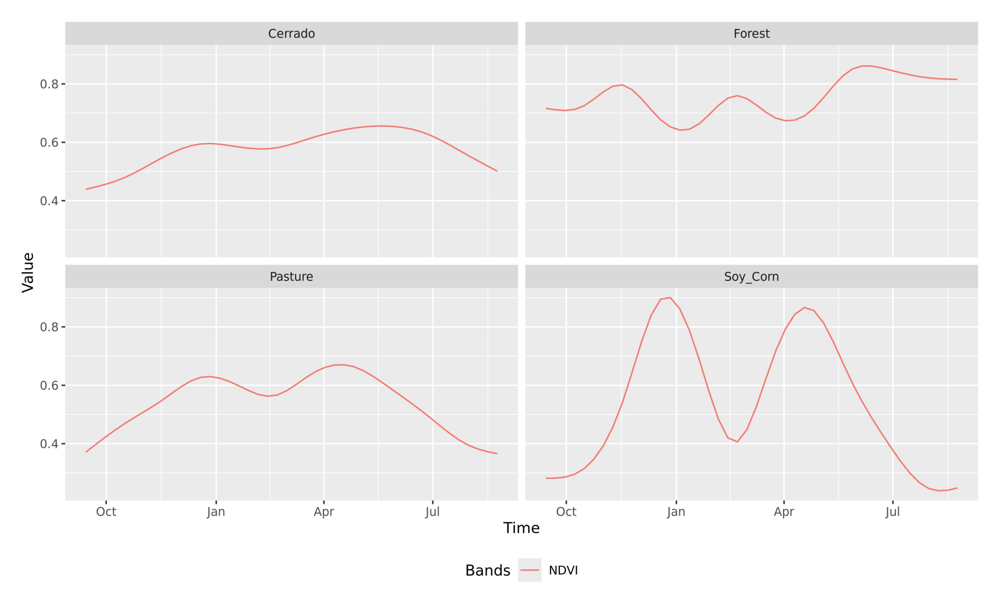

In [16]:
padroes = sits_patterns(amostras)
plot(padroes)

---
# Parte 5 — Operações com séries temporais

## 5.1 Um ponto de exemplo com 6 bandas
`point_mt_6bands` é **um único ponto** com série de 2000 a 2016 e 6 bandas (NDVI, EVI, BLUE, RED, NIR, MIR).

**Requer:** —

In [17]:
ponto = point_mt_6bands
sits_bands(ponto)

['MIR', 'BLUE', 'NIR', 'RED', 'EVI', 'NDVI']

## 5.2 Selecionar uma banda
**Função:** `sits_select(data, bands=...)`. Mantém só as bandas pedidas. Aqui o NDVI, porque o modelo será treinado só com NDVI.

**Requer:** —

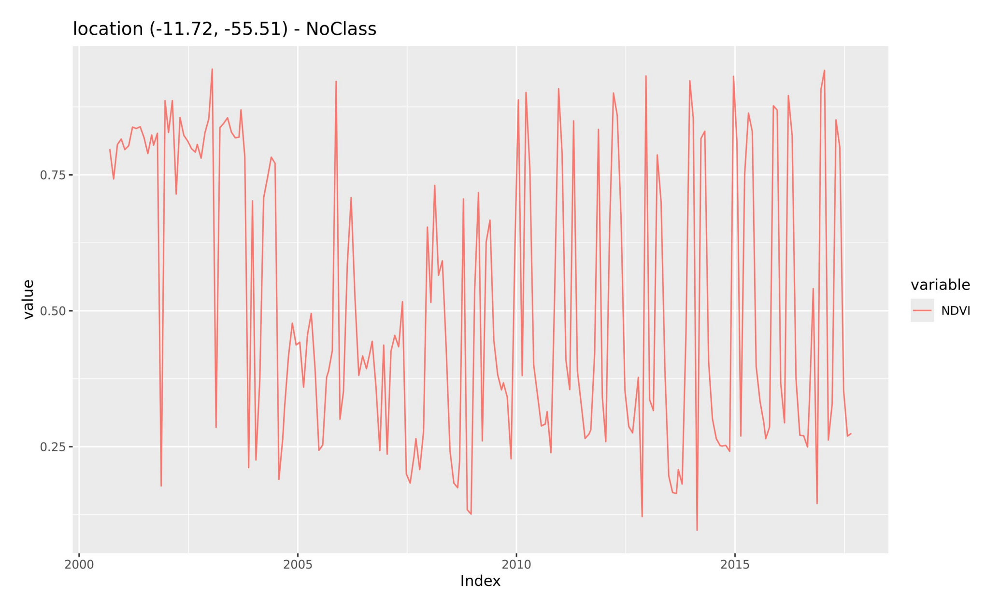

In [18]:
ponto_ndvi = sits_select(ponto, bands="NDVI")
plot(ponto_ndvi)

## 5.3 Suavizar com o filtro Savitzky-Golay
**Função:** `sits_sgolay(data, order, length)`. Ajusta polinômios locais para reduzir o ruído (nuvens, sombras), preservando picos e vales.
- `order`: grau do polinômio
- `length`: tamanho da janela (número de observações)

**Requer:** —

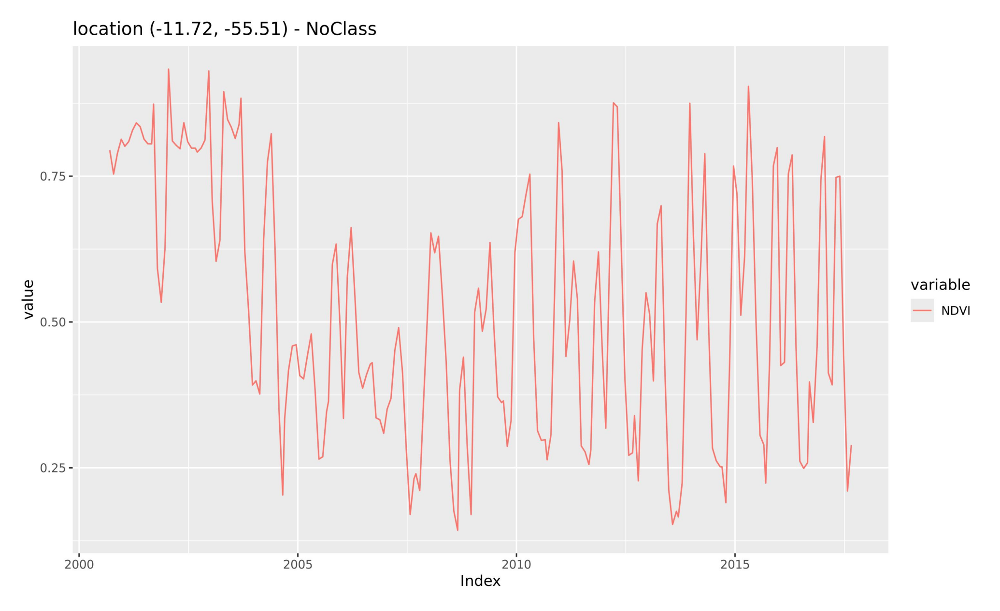

In [19]:
ponto_filtrado = sits_sgolay(ponto_ndvi, order=3, length=5)
plot(ponto_filtrado)

## 5.4 Calcular um índice a partir das bandas
**Função:** `sits_apply(data, NOVA_BANDA="expressão")`. Cria uma banda nova a partir de uma fórmula com as bandas existentes. Aqui o NDVI é recalculado com NIR e RED:

$$NDVI = \frac{NIR - RED}{NIR + RED}$$

**Requer:** —

In [20]:
ponto_indice = sits_apply(ponto, NDVI2="(NIR - RED) / (NIR + RED)")
sits_bands(ponto_indice)

['MIR', 'BLUE', 'NIR', 'RED', 'EVI', 'NDVI', 'NDVI2']

---
# Parte 6 — Treinar e validar um modelo
No sits, **método** (ex.: `sits_rfor()`) e **treino** (`sits_train()`) são separados: primeiro se descreve o algoritmo e seus parâmetros, depois ele é treinado com as amostras. O mesmo padrão vale para todos os algoritmos (RF, SVM, XGBoost, MLP, TempCNN, LightTAE...).

## 6.1 Treinar um Random Forest
**Funções:** `sits_rfor(num_trees=...)` descreve o algoritmo; `sits_train(samples, ml_method)` treina.

O **Random Forest** combina várias árvores de decisão. Cada data da série é tratada como uma variável. O mínimo aceito pelo sits é 20 árvores.

**Requer:** `randomForest`

In [21]:
modelo_rf = sits_train(samples=amostras, ml_method=sits_rfor(num_trees=100))
modelo_rf

## 6.2 Importância das variáveis
**Função:** `plot(modelo_rf)`. Mostra **quais datas** mais ajudam a separar as classes. Normalmente são as datas em que as curvas da seção 4.4 mais se diferenciam.

**Requer:** `randomForestExplainer`

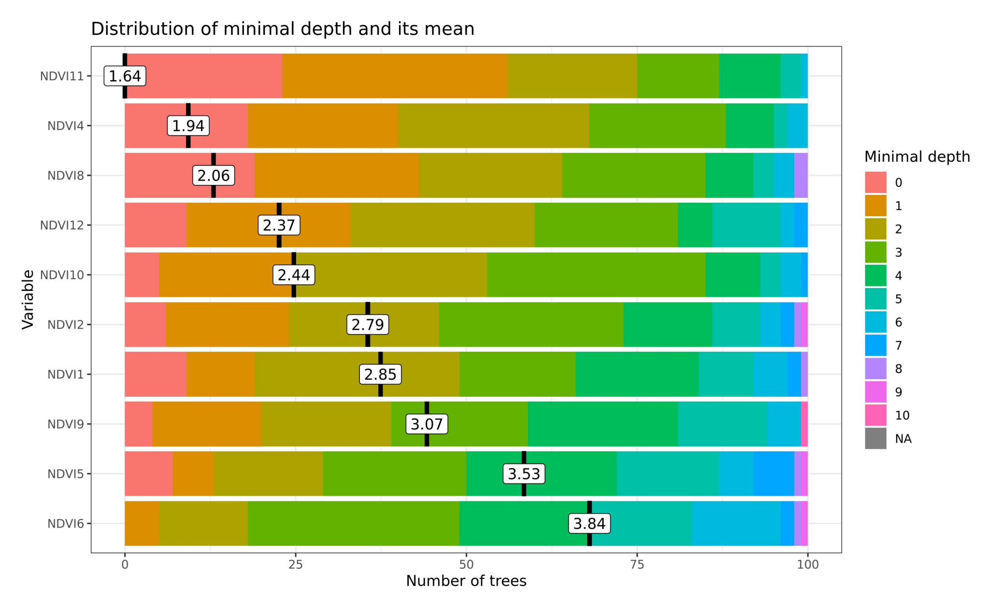

In [22]:
plot(modelo_rf)

## 6.3 Validação com 20% das amostras separadas
**Função:** `sits_validate(samples, validation_split, ml_method)`. Separa 20% das amostras, treina com os outros 80% e avalia nas separadas.

**Como interpretar a saída:**
- **Matriz de confusão:** linhas = classe prevista; colunas = classe real (referência)
- **Accuracy:** acurácia global
- **Kappa:** concordância descontando o acaso
- **Por classe:** *Sensitivity* = acurácia do produtor (omissão); *Pos Pred Value* = acurácia do usuário (comissão)

**Requer:** `caret`

In [23]:
validacao = sits_validate(amostras, validation_split=0.2, ml_method=sits_rfor(num_trees=50))
print(validacao)

Confusion Matrix and Statistics

          Reference
Prediction Cerrado Forest Pasture Soy_Corn
  Cerrado       69      1      14        0
  Forest         0     25       0        0
  Pasture        6      0      53        1
  Soy_Corn       1      0       2       72

Overall Statistics
                                          
               Accuracy : 0.8975          
                 95% CI : (0.8525, 0.9326)
    No Information Rate : 0.3115          
    P-Value [Acc > NIR] : < 2.2e-16       
                                          
                  Kappa : 0.8578          
                                          
 Mcnemar's Test P-Value : NA              

Statistics by Class:

                     Class: Cerrado Class: Forest Class: Pasture
Sensitivity                  0.9079        0.9615         0.7681
Specificity                  0.9107        1.0000         0.9600
Pos Pred Value               0.8214        1.0000         0.8833
Neg Pred Value               0.9563       

## 6.4 Validação cruzada k-fold
**Função:** `sits_kfold_validate(samples, folds, ml_method)`. Divide as amostras em *k* partes; cada parte é usada uma vez para teste. É mais robusta que uma divisão única, porque **todas** as amostras são testadas.

**Requer:** `caret` · **LibTorch** (a função consulta o torch internamente)

In [24]:
if not TORCH_OK:
    raise RuntimeError("Requer LibTorch: rode a célula 2.3 e reinicie o kernel.")

kfold = sits_kfold_validate(amostras, folds=5, ml_method=sits_rfor(num_trees=50))
print(kfold)

  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
  |======================================================================| 100%
Confusion Matrix and Statistics

          Reference
Prediction Pasture Soy_Corn Cerrado Forest
  Pasture      281        6      46      0
  Soy_Corn       4      358       0      0
  Cerrado       59        0     332      2
  Forest         0        0       1    129

Overall Statistics
                              
 Accuracy : 0.9031            
   95% CI : ( 0.8851, 0.9192 )
                              
    Kappa : 0.8658            

Statistics by Class:

                     Class: Pasture Class: Soy_Corn Class: Cerrado
Prod Acc (Recall)            0.8169          0.9835         0.8760


## 6.5 Deep learning: Multilayer Perceptron (MLP)
**Função:** `sits_mlp(epochs=...)`. Rede neural com camadas totalmente conectadas. `epochs` é o número de passagens pelos dados de treino. O gráfico mostra a **perda** e a **acurácia** a cada época: o ideal é a curva de validação acompanhar a de treino.

O sits também oferece redes feitas para séries temporais: `sits_tempcnn()`, `sits_lighttae()`, `sits_tae()`, `sits_resnet()`.

**Requer:** `torch`, `luz` · **LibTorch** · pode levar 1–2 min

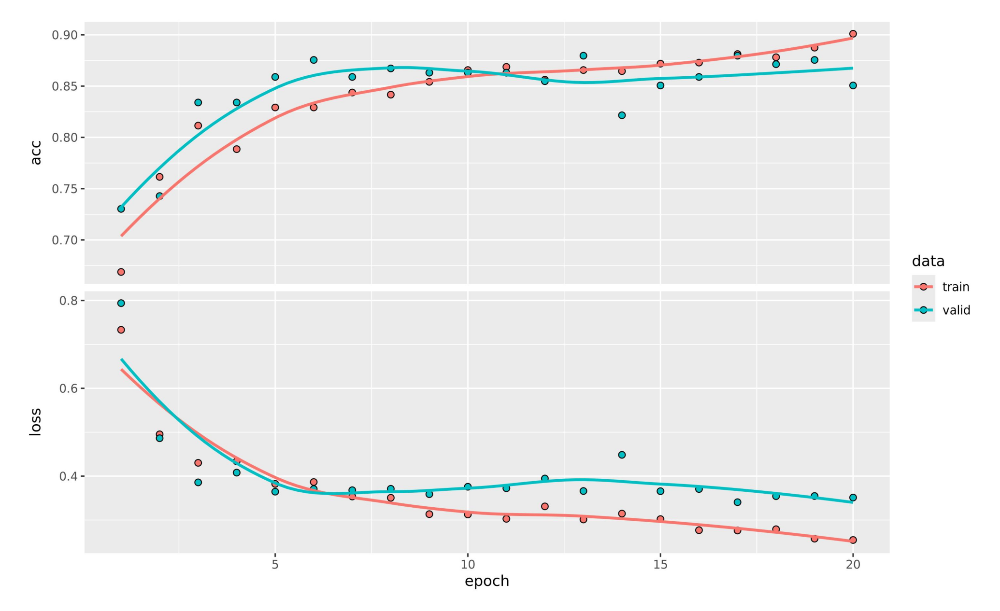

In [25]:
if not TORCH_OK:
    raise RuntimeError("Requer LibTorch: rode a célula 2.3 e reinicie o kernel.")

modelo_mlp = sits_train(samples=amostras, ml_method=sits_mlp(epochs=20))
plot(modelo_mlp)

---
# Parte 7 — Classificar uma série temporal

## 7.1 Classificar o ponto de exemplo
**Função:** `sits_classify(data, ml_model)`. O ponto tem 16 anos de dados, e o modelo foi treinado com séries de 1 ano. Por isso o sits **divide a série em intervalos anuais** e classifica cada um.

**Requer:** **LibTorch**: no sits 1.5.4, o `sits_classify` consulta o torch mesmo para o Random Forest

In [26]:
if not TORCH_OK:
    raise RuntimeError("Requer LibTorch: rode a célula 2.3 e reinicie o kernel.")

pred_ponto = sits_classify(data=ponto_ndvi, ml_model=modelo_rf)

  |======================================================================| 100%


## 7.2 Classe prevista em cada ano
**Função:** `sits_show_prediction()`. Uma linha por intervalo, com a classe mais provável. É assim que se acompanha a **trajetória** de uso da terra de um local (ex.: floresta → pastagem → soja).

**Requer:** resultado da 7.1

In [27]:
sits_show_prediction(pred_ponto)

,from,to,class
1,11213.0,11563.0,Forest
2,11579.0,11928.0,Forest
3,11944.0,12293.0,Forest
4,12309.0,12658.0,Cerrado
5,12674.0,13024.0,Pasture
6,13040.0,13389.0,Cerrado
7,13405.0,13754.0,Cerrado
8,13770.0,14119.0,Pasture
9,14135.0,14485.0,Cerrado
10,14501.0,14850.0,Soy_Corn


## 7.3 Série com a classificação
**Requer:** resultado da 7.1

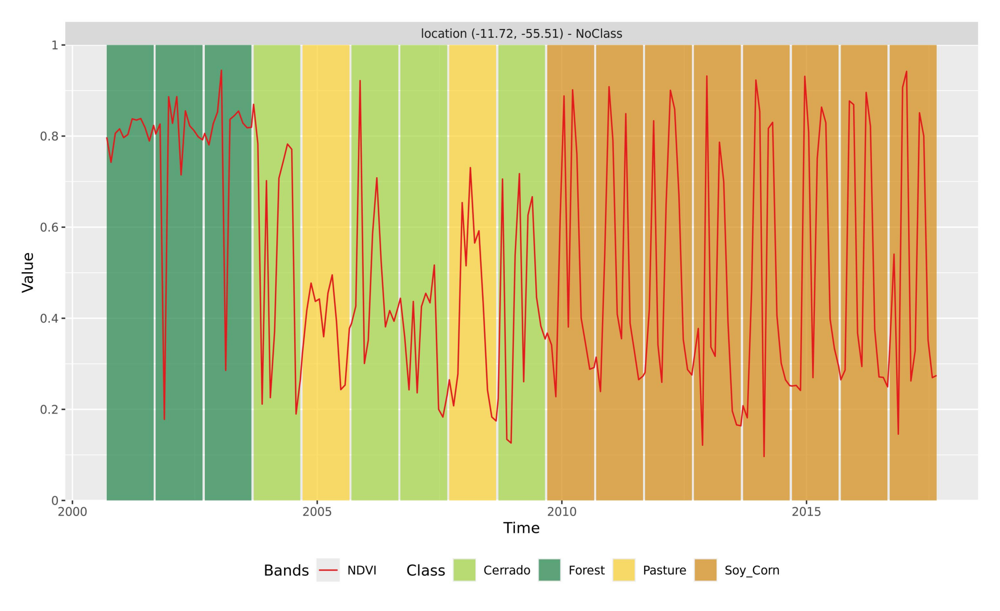

In [28]:
plot(pred_ponto)

---
# Parte 8 — Cubo de dados local
Um **cubo de dados** é um conjunto de imagens organizado em **x, y, tempo e banda**, com a mesma grade espacial e datas regulares. É a estrutura que o sits classifica para gerar mapas.

## 8.1 Localizar as imagens de exemplo
**Função:** `r_package_dir(caminho, package)`. Encontra uma pasta dentro de um pacote R instalado (equivale ao `system.file()` do R).

As imagens são composições MODIS MOD13Q1 (250 m, 16 dias) de NDVI da região de Sinop/MT, em formato `.jp2` (JPEG 2000).

**Requer:** —

In [29]:
data_dir = r_package_dir("extdata/raster/mod13q1", package="sits")
assert data_dir is not None and Path(data_dir).exists(), "Pasta de imagens do sits não encontrada"
print(data_dir)
sorted(p.name for p in Path(data_dir).iterdir())[:5]

/home/loren/miniforge3/envs/mlops_lulc/lib/R/library/sits/extdata/raster/mod13q1


['TERRA_MODIS_012010_NDVI_2013-09-14.jp2',
 'TERRA_MODIS_012010_NDVI_2013-10-16.jp2',
 'TERRA_MODIS_012010_NDVI_2013-11-17.jp2',
 'TERRA_MODIS_012010_NDVI_2013-12-19.jp2',
 'TERRA_MODIS_012010_NDVI_2014-01-17.jp2']

## 8.2 Criar o cubo
**Função:** `sits_cube(source, collection, data_dir)`. Monta o cubo lendo os arquivos. O sits extrai **tile, banda e data do nome do arquivo** (`TERRA_MODIS_012010_NDVI_2013-09-14.jp2`). `source` e `collection` dizem como interpretar os dados: aqui, como a coleção MODIS do BDC.

**Requer:** **driver JP2OpenJPEG**

In [30]:
if not JP2_OK:
    raise RuntimeError("GDAL sem driver JP2OpenJPEG. Rode no terminal: "
                       "mamba install -c conda-forge libgdal-jp2openjpeg  (e reinicie o kernel)")

cubo = sits_cube(source="BDC", collection="MOD13Q1-6.1", data_dir=data_dir)
assert len(cubo) > 0, "Cubo vazio: confira a pasta e o driver JP2."
cubo

  |======================================================================| 100%


In addition: Warning message:
Using `size` aesthetic for lines was deprecated in ggplot2 3.4.0.
ℹ Please use `linewidth` instead.
ℹ The deprecated feature was likely used in the randomForestExplainer package.
  Please report the issue to the authors.
This warning is displayed once per session.
Call `lifecycle::last_lifecycle_warnings()` to see where this warning was
generated. 


,source,collection,satellite,sensor,tile,xmin,xmax,ymin,ymax,crs,file_info
0,BDC,MOD13Q1-6.1,TERRA,MODIS,012010,-6.073798e+06,-6.014726e+06,-1.312333e+06,-1.278280e+06,"PROJCRS[""unnamed"",\n BASEGEOGCRS[""Unknown d...",fid band date nrows ncols ...


## 8.3 Bandas e datas do cubo
As datas do cubo precisam ser **compatíveis com as das amostras** usadas no treino: o modelo espera o mesmo número de observações.

**Requer:** —

In [31]:
print("Bandas:", sits_bands(cubo))
print("Datas: ", sits_timeline(cubo))

Bandas: ['NDVI']
Datas:  ['2013-09-14', '2013-10-16', '2013-11-17', '2013-12-19', '2014-01-17', '2014-02-18', '2014-03-22', '2014-04-23', '2014-05-25', '2014-06-26', '2014-07-28', '2014-08-29']


## 8.4 Extensão espacial
**Função:** `sits_bbox()`. Coordenadas do retângulo envolvente e o CRS do cubo.

**Requer:** —

In [32]:
sits_bbox(cubo)

,xmin,xmax,ymin,ymax,crs
1,-6.073798e+06,-6.014726e+06,-1.312333e+06,-1.278280e+06,"PROJCRS[""unnamed"",\n BASEGEOGCRS[""Unknown d..."


## 8.5 Visualizar o NDVI
**Função:** `plot(cubo, palette=...)`. Sem indicar a data, mostra a primeira. Verde = vegetação mais vigorosa.

**Requer:** `tmap`, `cols4all`, `RColorBrewer`

Registered S3 method overwritten by 'stars':
  method                  from
  st_interpolate_aw.stars sf  
Map saved to /tmp/tmp7vi4bsw2/tmap_plot.jpeg
Resolution: 3000 by 1800 pixels
Size: 10 by 6 inches (300 dpi)


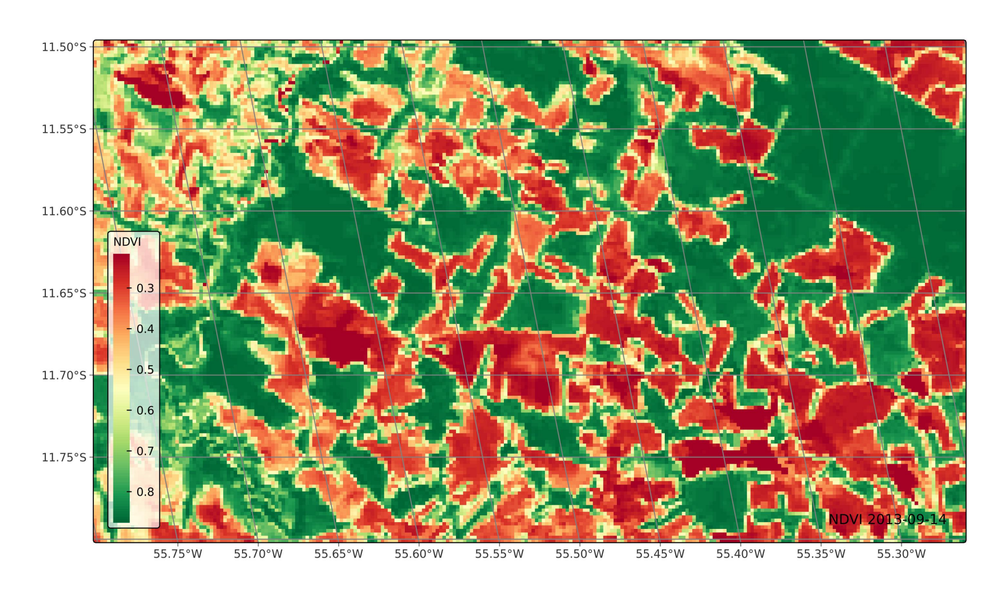

In [33]:
plot(cubo, palette="RdYlGn")

---
# Parte 9 — Classificação do cubo: do pixel ao mapa
O fluxo do sits tem **três etapas**, e cada uma grava arquivos novos em disco:

```
cubo 
──sits_classify──► probabilidades 
──sits_smooth──► probabilidades suavizadas 
──sits_label_classification──► mapa
```

Parâmetros comuns:
- `output_dir`: onde gravar
- `version`: sufixo nos nomes dos arquivos (evita sobrescrever)
- `multicores`: núcleos de CPU usados
- `memsize`: memória máxima em GB

## 9.1 Mapa de probabilidades por classe
**Função:** `sits_classify(data=cubo, ml_model, ...)`. Para cada pixel, calcula a **probabilidade de cada classe**. O resultado é um cubo de probabilidades (uma camada por classe). O gráfico mostra a probabilidade de Floresta.

**Requer:** **LibTorch** · JP2 

  |======================================================================| 100%


Map saved to /tmp/tmpv6vr_ng2/tmap_plot.jpeg
Resolution: 3000 by 1800 pixels
Size: 10 by 6 inches (300 dpi)


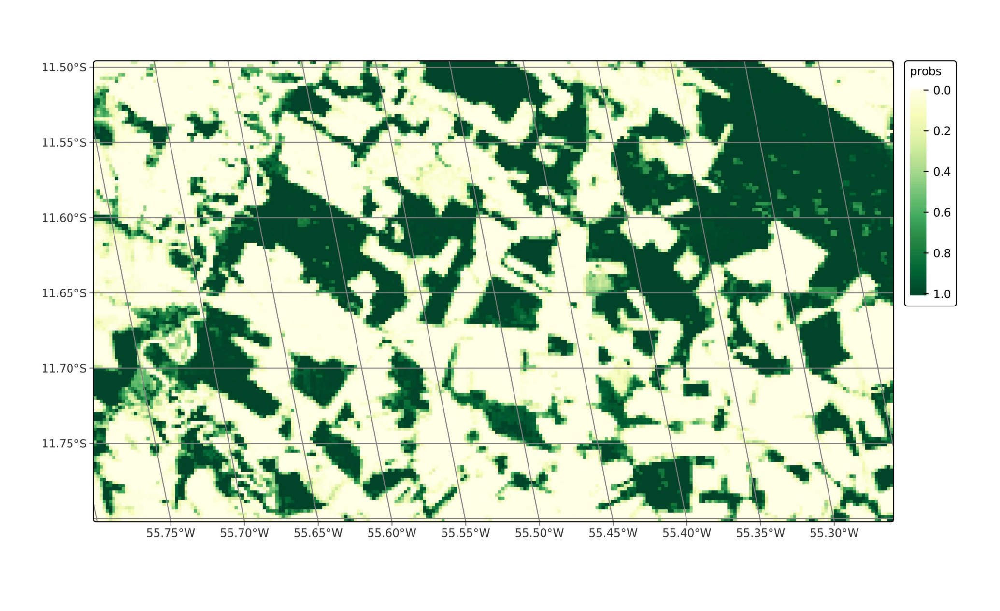

In [34]:
if not TORCH_OK:
    raise RuntimeError("Requer LibTorch: rode a célula 2.3 e reinicie o kernel.")

probs = sits_classify(
    data=cubo, ml_model=modelo_rf, output_dir=str(SAIDA),
    multicores=2, memsize=4, version="demo",
)
plot(probs, labels="Forest", palette="YlGn")

## 9.2 Suavização bayesiana
**Função:** `sits_smooth(cube, ...)`. Revisa a probabilidade de cada pixel levando em conta os **vizinhos**. Remove o efeito "sal e pimenta" (pixels isolados de outra classe) sem apagar bordas reais. Pixels vizinhos tendem a ser da mesma classe.

**Requer:** resultado da 9.1

  |======================================================================| 100%


Map saved to /tmp/tmpusylx1m4/tmap_plot.jpeg
Resolution: 3000 by 1800 pixels
Size: 10 by 6 inches (300 dpi)


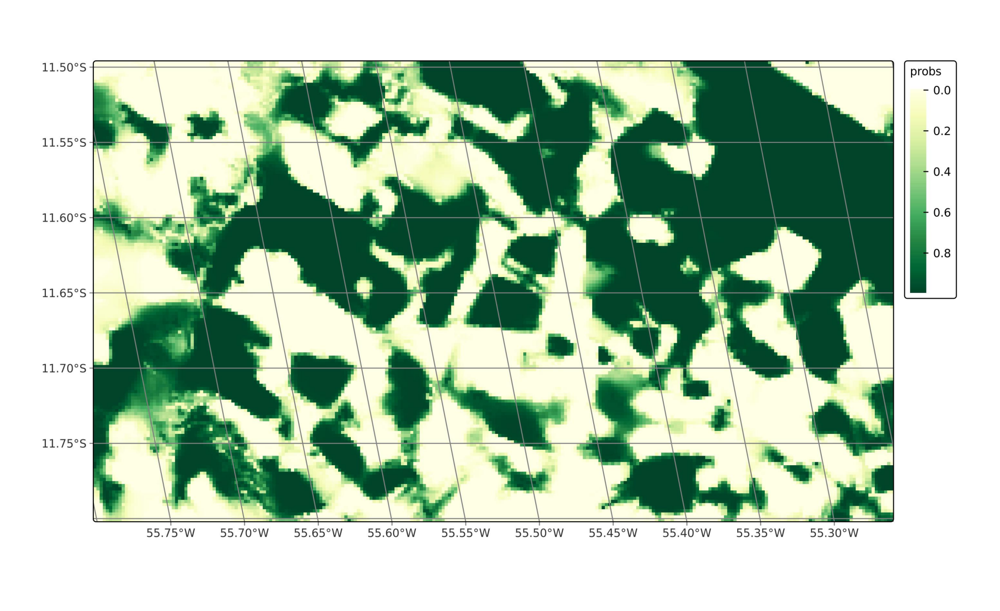

In [35]:
suave = sits_smooth(cube=probs, output_dir=str(SAIDA), multicores=2, memsize=4, version="demo")
plot(suave, labels="Forest", palette="YlGn")

## 9.3 Mapa final classificado
**Função:** `sits_label_classification(cube, ...)`. Atribui a cada pixel a **classe de maior probabilidade**.

**Requer:** resultado da 9.2

  |======================================================================| 100%


Map saved to /tmp/tmpxd1ujtqx/tmap_plot.jpeg
Resolution: 3000 by 1800 pixels
Size: 10 by 6 inches (300 dpi)


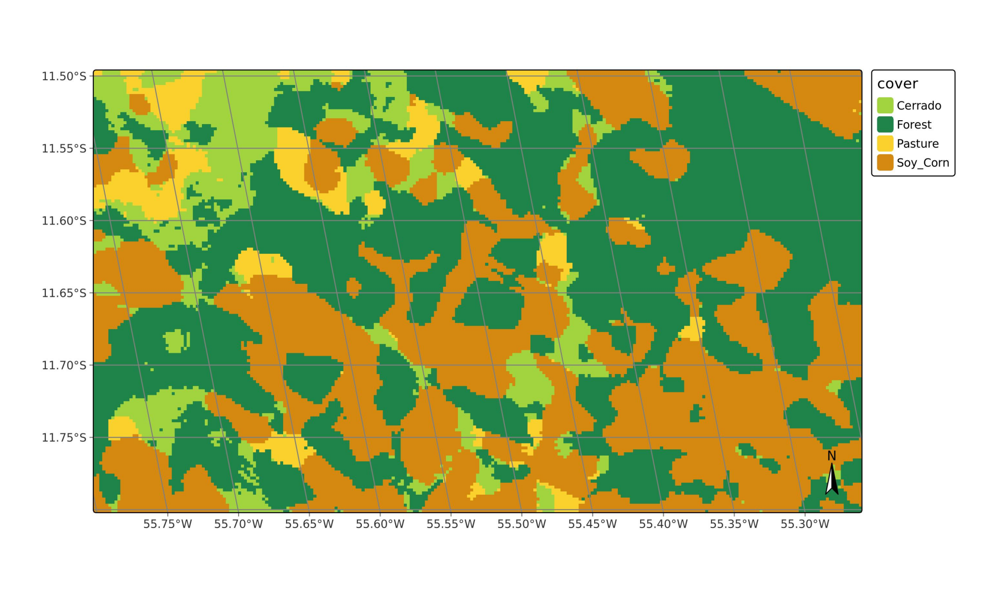

In [36]:
mapa = sits_label_classification(cube=suave, output_dir=str(SAIDA), version="demo")
plot(mapa)

---
# Parte 10 — Qualidade da classificação e aprendizado ativo
Um mapa sempre tem erros. O sits ajuda a descobrir **onde** o modelo está inseguro e **onde coletar novas amostras** para melhorá-lo (*active learning*).

## 10.1 Mapa de incerteza
**Função:** `sits_uncertainty(cube=probs, type=...)`. Com `type="margin"`, a incerteza vem da diferença entre as **duas classes mais prováveis**: margem pequena = incerteza alta. Outras opções: `"entropy"` e `"least"`.

**Requer:** resultado da 9.1

  |======================================================================| 100%


Map saved to /tmp/tmp0ze5lr6q/tmap_plot.jpeg
Resolution: 3000 by 1800 pixels
Size: 10 by 6 inches (300 dpi)


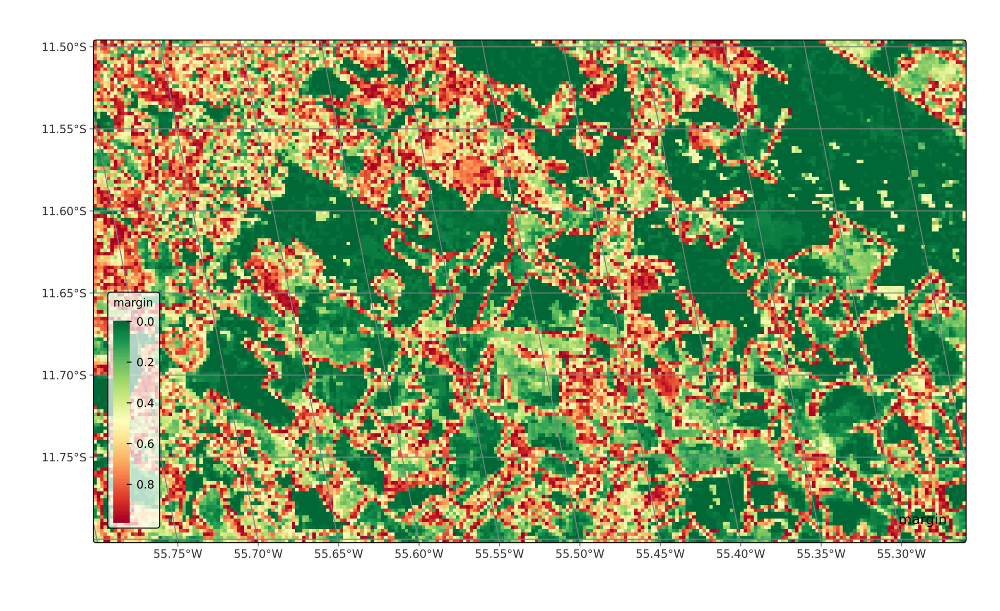

In [37]:
incerteza = sits_uncertainty(cube=probs, type="margin", output_dir=str(SAIDA), version="demo")
plot(incerteza)

## 10.2 Onde coletar novas amostras (pontos mais incertos)
**Função:** `sits_uncertainty_sampling(uncert_cube, n, min_uncert, sampling_window)`. Sugere até `n` pontos com incerteza acima de `min_uncert`. `sampling_window` evita pontos muito próximos entre si. O resultado vem **sem rótulo**: o analista identifica a classe (em campo ou numa imagem de alta resolução) e adiciona às amostras.

**Requer:** resultado da 10.1

In [38]:
sits_uncertainty_sampling(incerteza, n=10, min_uncert=0.4, sampling_window=10)

,longitude,latitude,uncertainty,start_date,end_date,label
1,-55.681511,-11.586458,1.0,2013-09-14,2014-08-29,NoClass
2,-55.262006,-11.796875,1.0,2013-09-14,2014-08-29,NoClass
3,-55.405753,-11.611458,1.0,2013-09-14,2014-08-29,NoClass
4,-55.556407,-11.694792,1.0,2013-09-14,2014-08-29,NoClass
5,-55.617880,-11.555208,1.0,2013-09-14,2014-08-29,NoClass
6,-55.736294,-11.605208,1.0,2013-09-14,2014-08-29,NoClass
7,-55.372137,-11.613542,1.0,2013-09-14,2014-08-29,NoClass
8,-55.352260,-11.673958,1.0,2013-09-14,2014-08-29,NoClass
9,-55.576778,-11.530208,1.0,2013-09-14,2014-08-29,NoClass
10,-55.644925,-11.690625,1.0,2013-09-14,2014-08-29,NoClass


## 10.3 Pontos de alta confiança
**Função:** `sits_confidence_sampling(probs_cube, n, min_margin, sampling_window)`. Sugere pontos onde o modelo está **muito seguro**, já com o rótulo previsto. São úteis para reforçar classes com poucas amostras.

> Esta função exige **`n ≥ 20`** (com `n=10` dá erro).

**Requer:** resultado da 9.1

In [39]:
sits_confidence_sampling(probs, n=20, min_margin=0.5, sampling_window=10)

  |======================================================================| 100%


,longitude,latitude,start_date,end_date,label,confidence
1,-55.688509,-11.801042,2013-09-14,2014-08-29,Cerrado,0.7750
2,-55.746072,-11.738542,2013-09-14,2014-08-29,Cerrado,0.7650
3,-55.749906,-11.736458,2013-09-14,2014-08-29,Cerrado,0.7500
4,-55.654501,-11.546875,2013-09-14,2014-08-29,Cerrado,0.7299
5,-55.747757,-11.746875,2013-09-14,2014-08-29,Cerrado,0.7049
...,...,...,...,...,...,...
76,-55.693640,-11.784375,2013-09-14,2014-08-29,Soy_Corn,0.6450
77,-55.700554,-11.607292,2013-09-14,2014-08-29,Soy_Corn,0.6400
78,-55.648478,-11.559375,2013-09-14,2014-08-29,Soy_Corn,0.6300
79,-55.653035,-11.582292,2013-09-14,2014-08-29,Soy_Corn,0.6300


## 10.4 Variância espacial das probabilidades
**Função:** `sits_variance(cube=probs, ...)`. Mede o quanto as probabilidades variam na vizinhança de cada pixel. Variância alta indica bordas ou áreas heterogêneas. Ajuda a escolher o grau de suavização da 9.2.

**Requer:** resultado da 9.1

  |======================================================================| 100%
[plot mode] fit legend/component: Some legend items or map compoments do not
fit well, and are therefore rescaled.
ℹ Set the tmap option `component.autoscale = FALSE` to disable rescaling.


Map saved to /tmp/tmpbd0spwxa/tmap_plot.jpeg
Resolution: 3000 by 1800 pixels
Size: 10 by 6 inches (300 dpi)


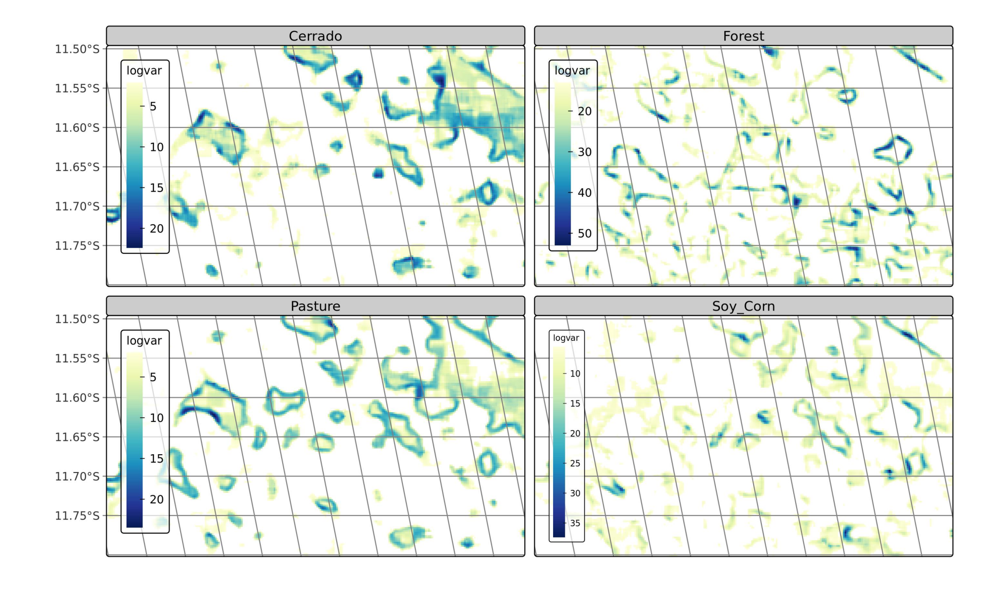

In [40]:
variancia = sits_variance(cube=probs, output_dir=str(SAIDA), multicores=2, memsize=4, version="demo")
plot(variancia)

---
# Parte 11 — Extrair séries temporais de um cubo
Na prática, as amostras de treino são criadas assim: um **arquivo de pontos** (CSV ou shapefile) com coordenadas e classe + um **cubo** → `sits_get_data` extrai a série de cada ponto.

## 11.1 Criar um CSV de pontos
O CSV precisa das colunas `longitude`, `latitude` (WGS84), `start_date`, `end_date` e `label`. Os pontos são criados perto do centro do cubo.

**Requer:** —

In [41]:
bb = sits_bbox(cubo, as_crs="EPSG:4326")
lon = (float(bb["xmin"].iloc[0]) + float(bb["xmax"].iloc[0])) / 2
lat = (float(bb["ymin"].iloc[0]) + float(bb["ymax"].iloc[0])) / 2
datas = sits_timeline(cubo)

pontos = pd.DataFrame({
    "id": [1, 2, 3],
    "longitude": [lon, lon + 0.02, lon - 0.02],
    "latitude": [lat, lat + 0.02, lat - 0.02],
    "start_date": [str(datas[0])] * 3,
    "end_date": [str(datas[-1])] * 3,
    "label": ["NoClass"] * 3,
})
csv_pontos = SAIDA / "pontos_demo.csv"
pontos.to_csv(csv_pontos, index=False)
pontos

,id,longitude,latitude,start_date,end_date,label
0,1,-55.500794,-11.648958,2013-09-14,2014-08-29,NoClass
1,2,-55.480794,-11.628958,2013-09-14,2014-08-29,NoClass
2,3,-55.520794,-11.668958,2013-09-14,2014-08-29,NoClass


## 11.2 Extrair as séries desses pontos
**Função:** `sits_get_data(cube, samples)`. Lê o valor de cada pixel em todas as datas e devolve uma tabela de amostras, no mesmo formato de `samples_modis_ndvi`.

**Requer:** `sf` · JP2

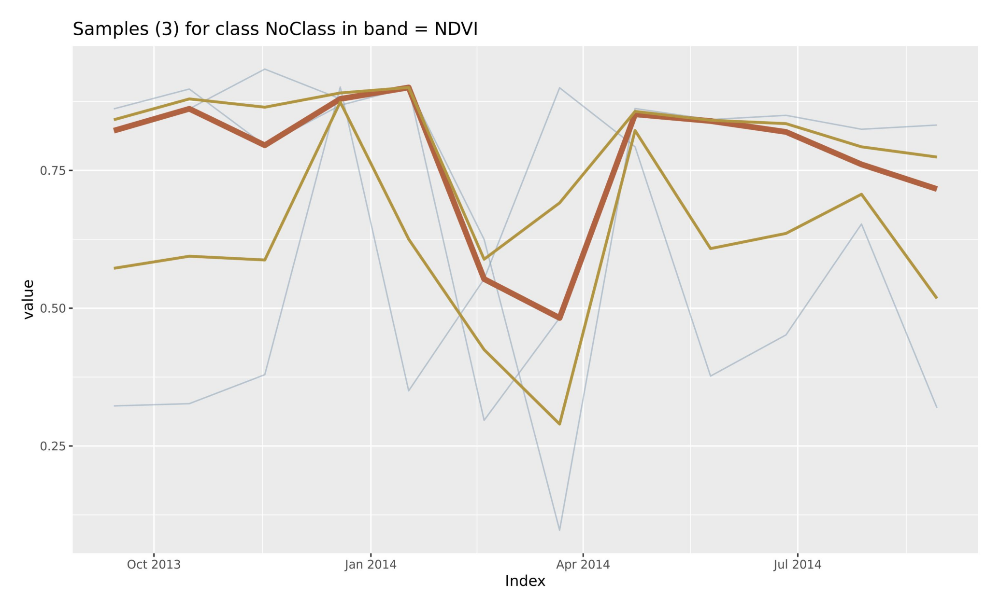

In [42]:
series = sits_get_data(cube=cubo, samples=str(csv_pontos))
plot(series)

---
# Parte 12 — Qualidade das amostras com SOM
Amostras com rótulo errado ou classes que se confundem prejudicam o modelo. O **Mapa Auto-Organizável (SOM)** agrupa séries parecidas em "neurônios" de uma grade 2D, **sem olhar o rótulo**. Depois o sits verifica se cada neurônio ficou "puro" (uma classe) ou "misturado".

## 12.1 Treinar o SOM
**Função:** `sits_som_map(data, grid_xdim, grid_ydim)`. Grade de 6 × 6 neurônios. Cada neurônio recebe a cor da classe majoritária.

**Requer:** `kohonen`

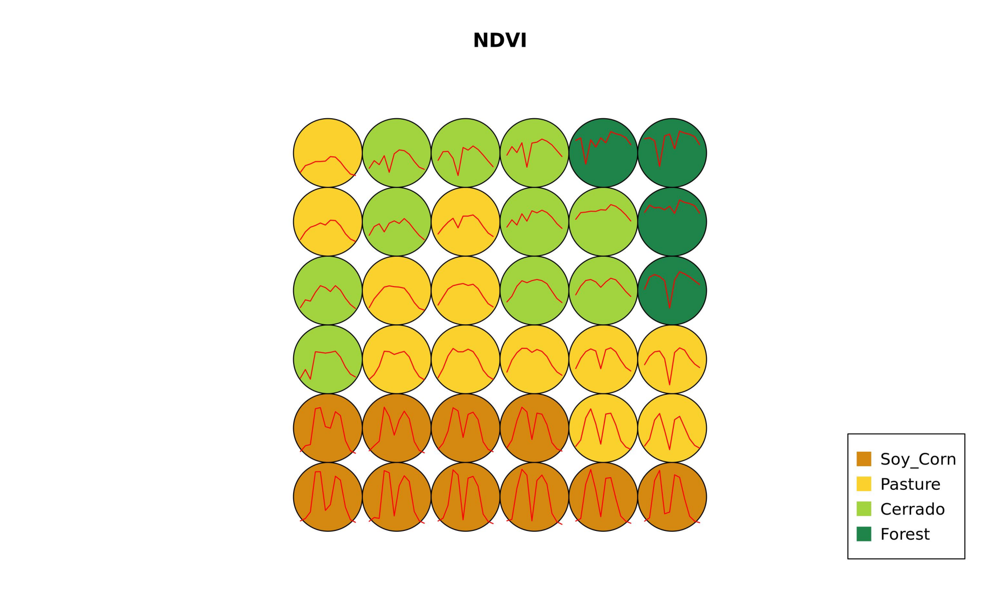

In [43]:
som = sits_som_map(amostras, grid_xdim=6, grid_ydim=6)
plot(som)

## 12.2 Mistura entre classes nos clusters
**Função:** `sits_som_evaluate_cluster(som)`. Mostra, para cada classe, que porcentagem das amostras caiu em neurônios de outras classes. Uma mistura alta indica classes difíceis de separar ou amostras ruidosas, que podem ser removidas com `sits_som_clean_samples()`.

**Requer:** resultado da 12.1

In [44]:
sits_som_evaluate_cluster(som)

,id_cluster,cluster,class,mixture_percentage
1,1,Cerrado,Cerrado,70.261438
2,1,Cerrado,Forest,0.980392
3,1,Cerrado,Pasture,27.450980
4,1,Cerrado,Soy_Corn,1.307190
5,2,Forest,Cerrado,22.424242
6,2,Forest,Forest,77.575758
7,3,Pasture,Cerrado,32.647815
8,3,Pasture,Pasture,65.038560
9,3,Pasture,Soy_Corn,2.313625
10,4,Soy_Corn,Pasture,1.955307


---
# Parte 13 — Exportar resultados
Converter os resultados para formatos e bibliotecas do ecossistema Python e GIS.

## 13.1 Amostras para CSV
**Função:** `sits_to_csv(data, file)`. Exporta os metadados das amostras (sem as séries).

**Requer:** —

In [45]:
sits_to_csv(amostras, file=str(SAIDA / "amostras.csv"))
pd.read_csv(SAIDA / "amostras.csv").head()

,id,longitude,latitude,start_date,end_date,label
0,1,-55.1852,-10.8378,2013-09-14,2014-08-29,Pasture
1,2,-57.7940,-9.7573,2006-09-14,2007-08-29,Pasture
2,3,-51.9412,-13.4198,2014-09-14,2015-08-29,Pasture
3,4,-55.9643,-10.0621,2005-09-14,2006-08-29,Pasture
4,5,-54.5540,-10.3749,2013-09-14,2014-08-29,Pasture


## 13.2 Amostras para GeoPandas
**Função:** `sits_as_geopandas(data)`. Vira um `GeoDataFrame` com geometria de ponto, pronto para análises espaciais ou para exportar para shapefile/GeoPackage.

**Requer:** `geopandas`

In [46]:
gdf = sits_as_geopandas(amostras)
gdf.head()

,longitude,latitude,start_date,end_date,label,cube,time_series,crs,geometry
1,-55.1852,-10.8378,2013-09-14,2014-08-29,Pasture,MOD13Q1,NestedDataFrame(size = 12),EPSG:4326,POINT (-55.1852 -10.8378)
2,-57.7940,-9.7573,2006-09-14,2007-08-29,Pasture,MOD13Q1,NestedDataFrame(size = 12),EPSG:4326,POINT (-57.794 -9.7573)
3,-51.9412,-13.4198,2014-09-14,2015-08-29,Pasture,MOD13Q1,NestedDataFrame(size = 12),EPSG:4326,POINT (-51.9412 -13.4198)
4,-55.9643,-10.0621,2005-09-14,2006-08-29,Pasture,MOD13Q1,NestedDataFrame(size = 12),EPSG:4326,POINT (-55.9643 -10.0621)
5,-54.5540,-10.3749,2013-09-14,2014-08-29,Pasture,MOD13Q1,NestedDataFrame(size = 12),EPSG:4326,POINT (-54.554 -10.3749)


## 13.3 Cubo para xarray
**Função:** `sits_as_xarray(cube)`. Vira um `xarray.Dataset` (dimensões x, y, tempo). Permite usar o ecossistema Python de dados multidimensionais. Os rasters são lidos pelo `rioxarray`, que também depende do driver JP2.

**Requer:** `xarray`, `rioxarray`, `dask` · JP2

In [47]:
sits_as_xarray(cubo)

<xarray.Dataset> Size: 2MB
Dimensions:      (time: 12, y: 148, x: 255)
Coordinates:
  * time         (time) datetime64[ns] 96B 2013-09-14 2013-10-16 ... 2014-08-29
  * y            (y) float64 1kB -1.278e+06 -1.279e+06 ... -1.312e+06 -1.312e+06
  * x            (x) float64 2kB -6.074e+06 -6.073e+06 ... -6.015e+06 -6.015e+06
    spatial_ref  int64 8B 0
Data variables:
    NDVI         (time, y, x) float32 2MB dask.array<chunksize=(1, 148, 255), meta=np.ndarray>

## 13.4 Estilo de cores para o QGIS
**Função:** `sits_colors_qgis(cube, file)`. Gera um arquivo `.qml` com as cores das classes. No QGIS: *Propriedades da camada → Estilo → Carregar estilo*.

**Requer:** mapa classificado (9.3)

In [48]:
sits_colors_qgis(mapa, file=str(SAIDA / "mapa.qml"))
print("Estilo salvo em:", SAIDA / "mapa.qml")

Estilo salvo em: /tmp/demo_pysits/mapa.qml


## 13.5 Tabela de cores do sits
**Função:** `sits_colors()`. Cores padrão associadas aos nomes de classes. Podem ser alteradas com `sits_colors_set()`.

**Requer:** —

In [49]:
sits_colors()

,name,color
1,Evergreen_Broadleaf_Forest,#1E8449
2,Evergreen_Broadleaf_Forests,#1E8449
3,Tree_Cover_Broadleaved_Evergreen,#1E8449
4,Forest,#1E8449
5,Forests,#1E8449
...,...,...
236,"Rice, Germination",#F6DDCC
237,"Rice, Tillering",#EDBB99
238,"Rice, Stem elong.",#E59866
239,"Rice, Booting",#DC7633


## 13.6 Arquivos gerados
Os rasters de probabilidade, suavização, mapa, incerteza e variância ficam em `SAIDA` como **GeoTIFF**, prontos para abrir no QGIS.

In [50]:
sorted(p.name for p in SAIDA.iterdir())

['.sits',
 'TERRA_MODIS_012010_2013-09-14_2014-08-29_bayes_demo.tif',
 'TERRA_MODIS_012010_2013-09-14_2014-08-29_class_demo.tif',
 'TERRA_MODIS_012010_2013-09-14_2014-08-29_margin_demo.tif',
 'TERRA_MODIS_012010_2013-09-14_2014-08-29_probs_demo.tif',
 'TERRA_MODIS_012010_2013-09-14_2014-08-29_variance_demo.tif',
 'amostras.csv',
 'mapa.qml',
 'pontos_demo.csv']

---
# Parte 14 — Resumo

**Fluxo completo do sits**
```
amostras ─► (filtros, índices) ─► sits_train ─► sits_validate / sits_kfold_validate
                                     │
cubo ────────────────────────────────┴─► sits_classify ─► sits_smooth ─► sits_label_classification ─► mapa
                                              │
                                              └─► sits_uncertainty ─► novas amostras (active learning)
```

**Conclusões**
1. O PySITS é uma **ponte para o R**: precisa de Python, R e bibliotecas de sistema funcionando juntos.
2. **Versões iguais:** `pysits` 1.5.4 ↔ `sits` 1.5.4.
3. No Linux/WSL, instale os pacotes R pelo **conda-forge**, que já vem compilado. Do CRAN, só o que não existe lá (`randomForestExplainer`).
4. **LibTorch** é obrigatório no sits 1.5.4 para classificar: `install_torch()` com `CUDA=cpu` e `options(timeout=1800)`.
5. **Driver JP2OpenJPEG** para ler as imagens `.jp2`: `libgdal-jp2openjpeg`.
6. Quando algo falhar, rode o **checklist da seção 2.2** e leia os avisos do R (reativados na 2.5).

**Referências**
- Livro do sits (exemplos em R e Python): https://e-sensing.github.io/sitsbook/
- Repositório do PySITS: https://github.com/e-sensing/pysits
- Repositório do sits: https://github.com/e-sensing/sits
- Simoes, R. et al. (2021). *Satellite Image Time Series Analysis for Big Earth Observation Data*. Remote Sensing, 13(13), 2428.